# A minimal ReAct agent, built by hand

**ReAct** (Yao et al., 2022) lets a language model alternate between **thinking** ("what do I need next?") and **acting** (calling a tool), with each tool result fed back to the model as an **observation**. This notebook builds that loop from scratch, with no agent library.

## Part 0: Setup

In [ ]:
%pip install -q transformers accelerate

In [2]:
import os, re, math, difflib, textwrap, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 200)

# ---- settings you may change -------------------------------------------------
BACKEND    = os.environ.get("REACT_BACKEND", "hf")                 # "hf" (real model) or "mock" (scripted, offline)
MODEL_NAME = os.environ.get("MODEL_NAME", "Qwen/Qwen2.5-3B")       # a BASE model. Smaller/faster: "Qwen/Qwen2.5-1.5B"
SCALE      = os.environ.get("REACT_SCALE", "default")              # "fast" = 6 questions, "default" = all 15
MAX_STEPS  = 6                                                     # step limit for the agent loop
# -----------------------------------------------------------------------------
print("backend:", BACKEND, "| model:", MODEL_NAME if BACKEND == "hf" else "(scripted stand-in)", "| scale:", SCALE, "| max steps:", MAX_STEPS)

backend: hf | model: Qwen/Qwen2.5-3B | scale: default | max steps: 6


# Part 1: The tool

An agent needs something to act on. We use a small built-in knowledge base of short encyclopaedia-style paragraphs, keyed by title. The tool mirrors the one in the paper's Wikipedia setup:

* `Search[entity]` returns the paragraph for that title.
* If there is no such title, it returns `Could not find [entity]. Similar: [...]` with the closest titles, so a model that guessed the wrong name can recover.

The facts are real, but they are a toy knowledge base: **only what is in this dictionary can be found**.

In [3]:
KB = {
    "Marie Curie": "Marie Curie (born 7 November 1867 in Warsaw, died 1934) was a Polish-French physicist and chemist. She won the Nobel Prize in Physics in 1903 and the Nobel Prize in Chemistry in 1911. She discovered the elements polonium and radium.",
    "Pierre Curie": "Pierre Curie (born 15 May 1859 in Paris, died 1906) was a French physicist. He shared the 1903 Nobel Prize in Physics with Marie Curie and Henri Becquerel.",
    "Alan Turing": "Alan Turing (born 23 June 1912 in London, died 1954) was an English mathematician and computer scientist. He formalised the concepts of algorithm and computation with the Turing machine.",
    "Ada Lovelace": "Ada Lovelace (born 10 December 1815 in London, died 1852) was an English mathematician. Her 1843 notes on Charles Babbage's Analytical Engine include what is regarded as the first published algorithm intended for a machine.",
    "Charles Babbage": "Charles Babbage (born 26 December 1791 in London, died 1871) was an English mathematician. He designed the Analytical Engine, an early concept for a general-purpose computer.",
    "Mount Kilimanjaro": "Mount Kilimanjaro is a dormant volcano in Tanzania. With a summit of 5,895 m at Uhuru Peak, it is the highest mountain in Africa.",
    "Tanzania": "Tanzania is a country in East Africa. Its capital is Dodoma, and its largest city is Dar es Salaam.",
    "Linux": "Linux is a family of open-source operating systems based on the Linux kernel. The kernel was first released on 17 September 1991 by Linus Torvalds.",
    "Linus Torvalds": "Linus Torvalds (born 28 December 1969 in Helsinki, Finland) is a Finnish-American software engineer. He created the Linux kernel and the version control system Git.",
    "Finland": "Finland is a Nordic country in Northern Europe. Its capital and largest city is Helsinki.",
    "Eiffel Tower": "The Eiffel Tower is a wrought-iron lattice tower on the Champ de Mars in Paris, France. It was built by the company of Gustave Eiffel and completed in 1889 for the World's Fair.",
    "Gustave Eiffel": "Gustave Eiffel (born 15 December 1832 in Dijon, died 1923) was a French civil engineer. His company built the Eiffel Tower and the internal structure of the Statue of Liberty.",
    "Statue of Liberty": "The Statue of Liberty is a colossal neoclassical sculpture on Liberty Island in New York Harbor. A gift from France, it was dedicated in 1886 and designed by the sculptor Frédéric Auguste Bartholdi.",
    "Frédéric Auguste Bartholdi": "Frédéric Auguste Bartholdi (born 2 August 1834 in Colmar, France, died 1904) was a French sculptor best known for designing the Statue of Liberty.",
    "Chinua Achebe": "Chinua Achebe (born 16 November 1930 in Ogidi, Nigeria, died 2013) was a Nigerian novelist and critic. His first novel, Things Fall Apart (1958), is among the most widely read books in African literature.",
    "Things Fall Apart": "Things Fall Apart is a 1958 novel by the Nigerian author Chinua Achebe. It describes pre-colonial life in an Igbo society and the arrival of European colonisers.",
    "Wole Soyinka": "Wole Soyinka (born 13 July 1934 in Abeokuta, Nigeria) is a Nigerian playwright and poet. In 1986 he became the first African winner of the Nobel Prize in Literature.",
    "Nigeria": "Nigeria is a country in West Africa. Its capital is Abuja, and its largest city is Lagos. It became independent from the United Kingdom in 1960.",
    "Apollo 11": "Apollo 11 was the July 1969 spaceflight that first landed humans on the Moon. Neil Armstrong was the first to step onto the surface, followed by Buzz Aldrin, while Michael Collins stayed in orbit.",
    "Neil Armstrong": "Neil Armstrong (born 5 August 1930 in Wapakoneta, Ohio, died 25 August 2012) was an American astronaut. He was the first person to walk on the Moon, in 1969.",
    "Buzz Aldrin": "Buzz Aldrin (born 20 January 1930 in Glen Ridge, New Jersey) is an American astronaut. He was the second person to walk on the Moon, during Apollo 11.",
    "Mona Lisa": "The Mona Lisa is a portrait painting by Leonardo da Vinci, painted in the early 16th century. It is held in the Louvre museum.",
    "Louvre": "The Louvre is the world's most-visited art museum, located in Paris, France. It holds the Mona Lisa.",
    "Leonardo da Vinci": "Leonardo da Vinci (born 15 April 1452 in Vinci, Italy, died 1519) was an Italian painter, engineer and scientist.",
    "Python (programming language)": "Python is a high-level programming language created by Guido van Rossum and first released in 1991.",
    "Guido van Rossum": "Guido van Rossum (born 31 January 1956 in the Netherlands) is a Dutch programmer who created the Python programming language.",
    "World Wide Web": "The World Wide Web is an information system on the Internet in which documents are linked by hyperlinks. It was invented by Tim Berners-Lee in 1989 at CERN.",
    "Tim Berners-Lee": "Tim Berners-Lee (born 8 June 1955 in London) is an English computer scientist. He invented the World Wide Web in 1989 while working at CERN.",
    "CERN": "CERN is a European physics research organisation founded in 1954. It is based near Geneva, Switzerland, on the border with France.",
    "Nile": "The Nile is a river in Africa, about 6,650 km long, often regarded as the longest river in the world. It flows north into the Mediterranean Sea.",
    "Amazon River": "The Amazon River is a river in South America, about 6,400 km long. It has the largest discharge of any river in the world.",
    "Mount Everest": "Mount Everest is Earth's highest mountain above sea level, at 8,849 m. It lies in the Himalayas on the border between Nepal and China.",
}
TITLES = list(KB)
print(f"{len(KB)} articles. First three titles: {TITLES[:3]}")

32 articles. First three titles: ['Marie Curie', 'Pierre Curie', 'Alan Turing']


In [4]:
def kb_search(entity, max_sentences=5):
    # The one tool. Exact title match (ignoring case), else the closest titles.
    key = entity.strip().lower()
    for title, text in KB.items():
        if title.lower() == key:
            return " ".join(re.split(r"(?<=[.!?])\s+", text)[:max_sentences])
    contains = [t for t in TITLES if key and (key in t.lower() or t.lower() in key)]
    close = difflib.get_close_matches(entity.strip(), TITLES, n=5, cutoff=0.4)
    similar = list(dict.fromkeys(contains + close))[:5]
    return f"Could not find [{entity.strip()}]. Similar: {similar}"


for q in ["Marie Curie", "marie curie", "Everest", "Isaac Newton", "Python"]:
    print(f"Search[{q}]\n   -> {kb_search(q)}\n")

Search[Marie Curie]
   -> Marie Curie (born 7 November 1867 in Warsaw, died 1934) was a Polish-French physicist and chemist. She won the Nobel Prize in Physics in 1903 and the Nobel Prize in Chemistry in 1911. She discovered the elements polonium and radium.

Search[marie curie]
   -> Marie Curie (born 7 November 1867 in Warsaw, died 1934) was a Polish-French physicist and chemist. She won the Nobel Prize in Physics in 1903 and the Nobel Prize in Chemistry in 1911. She discovered the elements polonium and radium.

Search[Everest]
   -> Could not find [Everest]. Similar: ['Mount Everest', 'Louvre']

Search[Isaac Newton]
   -> Could not find [Isaac Newton]. Similar: []

Search[Python]
   -> Could not find [Python]. Similar: ['Python (programming language)']



### 📋 Report · Part 1: The tool

**What was built.** A dictionary `KB` of **32 short articles** and one function, `kb_search(entity)`. Five of the articles (Nile, Amazon River, Statue of Liberty, Bartholdi, Mount Everest) are used by the worked examples in the prompt; the rest are for the questions.

**How the search behaves**
1. If the text equals a title (ignoring case), return the article (first 5 sentences).
2. Otherwise return `Could not find [x]. Similar: [...]`, where the suggestions are titles that *contain* the text (or are contained in it) plus titles with similar spelling.

**Why this matters later**
- The tool wants an **entity title**, not a description. A query such as `Charles Babbage birth year` is a miss, though it still suggests `Charles Babbage` because the title is *inside* the query. `First person to walk on the Moon` is a miss with **no** suggestion at all, because no title is inside it.
- This is a **closed world**: the agent can only find what is in these 32 entries. The facts are real but short (for example, Nigeria's article gives the capital as Abuja).
- The suggestions are based on **spelling similarity, not meaning**. `Louvre` for `Everest` is already junk. This matters in Part 7, where a wrong suggestion sends the model off course.



# Part 2: The prompt

A ReAct prompt is an instruction followed by a few **worked examples** (the paper uses 3 to 6 and found more did not help), then the new question. Each example shows the format the model must copy:

```
Question: ...
Thought 1: ...        <- the model reasons about what to do next
Action 1: Search[x]   <- the model names a tool call
Observation 1: ...    <- the HARNESS (not the model) writes this, from the tool
...
Thought n: ...
Action n: Finish[answer]
```

We store each example as data, then **render** it in four styles, so the baselines see exactly the same examples. The observations in the examples are produced by calling the tool tool, so they are consistent with it. 

In [5]:
EXEMPLARS = [
    dict(question="Which is longer, the Nile or the Amazon River?",
         steps=[("I need the length of both rivers. Start with the Nile.", "Nile"),
                ("The Nile is about 6,650 km long. Now I need the Amazon River.", "Amazon River")],
         final_thought="The Amazon River is about 6,400 km, which is shorter than the Nile's 6,650 km, so the Nile is longer.",
         answer="Nile",
         cot="The Nile is about 6,650 km long and the Amazon River about 6,400 km, so the Nile is longer."),
    dict(question="In what year was the designer of the Statue of Liberty born?",
         steps=[("I need to find who designed the Statue of Liberty, then the year that person was born.", "Statue of Liberty"),
                ("The Statue of Liberty was designed by Frédéric Auguste Bartholdi. Now I need his birth year.", "Frédéric Auguste Bartholdi")],
         final_thought="Bartholdi was born in 1834, so the answer is 1834.",
         answer="1834",
         cot="The Statue of Liberty was designed by Frédéric Auguste Bartholdi, who was born in 1834."),
    dict(question="How tall is the highest mountain on Earth?",
         steps=[("The highest mountain on Earth is Everest. I need its height. Search Everest.", "Everest"),
                ("The search did not find Everest but suggests Mount Everest, so I will search that.", "Mount Everest")],
         final_thought="Mount Everest is 8,849 m high, so the answer is 8,849 m.",
         answer="8,849 m",
         cot="The highest mountain on Earth is Mount Everest, which is 8,849 m high."),
]

INSTRUCTIONS = {
    "react":    "Answer each question by interleaving Thought, Action and Observation steps. Thought reasons about what to do next. Action is Search[entity] to look an entity up, or Finish[answer] when you know the answer. Observation is the result of the search.",
    "act":      "Answer each question using Actions and Observations. Action is Search[entity] to look an entity up, or Finish[answer] when you know the answer. Observation is the result of the search.",
    "cot":      "Answer each question. Think step by step in a Thought, then give the Answer.",
    "standard": "Answer each question.",
}


def render_exemplar(ex, style):
    q = f"Question: {ex['question']}\n"
    if style == "standard":
        return q + f"Answer: {ex['answer']}\n"
    if style == "cot":
        return q + f"Thought: {ex['cot']}\nAnswer: {ex['answer']}\n"
    out, n = q, 0
    for thought, entity in ex["steps"]:
        n += 1
        if style == "react":
            out += f"Thought {n}: {thought}\n"
        out += f"Action {n}: Search[{entity}]\nObservation {n}: {kb_search(entity)}\n"
    n += 1
    if style == "react":
        out += f"Thought {n}: {ex['final_thought']}\n"
    out += f"Action {n}: Finish[{ex['answer']}]\n"
    return out


def build_prompt(question, style):
    shots = "\n".join(render_exemplar(ex, style) for ex in EXEMPLARS)
    return f"{INSTRUCTIONS[style]}\n\n{shots}\nQuestion: {question}\n"


print(build_prompt("<NEW QUESTION GOES HERE>", "react"))

Answer each question by interleaving Thought, Action and Observation steps. Thought reasons about what to do next. Action is Search[entity] to look an entity up, or Finish[answer] when you know the answer. Observation is the result of the search.

Question: Which is longer, the Nile or the Amazon River?
Thought 1: I need the length of both rivers. Start with the Nile.
Action 1: Search[Nile]
Observation 1: The Nile is a river in Africa, about 6,650 km long, often regarded as the longest river in the world. It flows north into the Mediterranean Sea.
Thought 2: The Nile is about 6,650 km long. Now I need the Amazon River.
Action 2: Search[Amazon River]
Observation 2: The Amazon River is a river in South America, about 6,400 km long. It has the largest discharge of any river in the world.
Thought 3: The Amazon River is about 6,400 km, which is shorter than the Nile's 6,650 km, so the Nile is longer.
Action 3: Finish[Nile]

Question: In what year was the designer of the Statue of Liberty bo

In [6]:
for style in ["act", "cot", "standard"]:
    print(f"=============== {style} style: the first example only ===============")
    print(render_exemplar(EXEMPLARS[1], style))

=============== act style: the first example only ===============
Question: In what year was the designer of the Statue of Liberty born?
Action 1: Search[Statue of Liberty]
Observation 1: The Statue of Liberty is a colossal neoclassical sculpture on Liberty Island in New York Harbor. A gift from France, it was dedicated in 1886 and designed by the sculptor Frédéric Auguste Bartholdi.
Action 2: Search[Frédéric Auguste Bartholdi]
Observation 2: Frédéric Auguste Bartholdi (born 2 August 1834 in Colmar, France, died 1904) was a French sculptor best known for designing the Statue of Liberty.
Action 3: Finish[1834]

=============== cot style: the first example only ===============
Question: In what year was the designer of the Statue of Liberty born?
Thought: The Statue of Liberty was designed by Frédéric Auguste Bartholdi, who was born in 1834.
Answer: 1834

=============== standard style: the first example only ===============
Question: In what year was the designer of the Statue of Libert

**Things to notice.** The CoT thought ("designed by Bartholdi, who was born in 1834") is a fact the model must **recall from memory**. In ReAct that same fact has to be **looked up**. That is the core comparison of the whole notebook: reasoning without a tool versus reasoning with one.

# Part 3: The questions

Fifteen questions with a short gold answer, in four kinds:

| kind | what it needs |
|---|---|
| `compare` | two lookups, then compare (who was born first?) |
| `two_hop` | the answer to the first lookup tells you what to look up next |
| `one_hop` | a single lookup |
| `kb_gap` | the knowledge base **lacks** a needed article (a trap: can the model fall back on what it knows, or does it loop?) |

All the facts are in the knowledge base, except for the trap.

In [7]:
QUESTIONS = [
    dict(id=1,  kind="compare", question="Who was born first, Marie Curie or Alan Turing?", gold="Marie Curie"),
    dict(id=2,  kind="compare", question="Who was born first, Charles Babbage or Ada Lovelace?", gold="Charles Babbage"),
    dict(id=3,  kind="compare", question="Who was born first, Chinua Achebe or Wole Soyinka?", gold="Chinua Achebe"),
    dict(id=15, kind="compare", question="Who was born first, Pierre Curie or Marie Curie?", gold="Pierre Curie"),
    dict(id=4,  kind="two_hop", question="What is the capital of the country where Mount Kilimanjaro is located?", gold="Dodoma"),
    dict(id=5,  kind="two_hop", question="In which country was the creator of Linux born?", gold="Finland"),
    dict(id=6,  kind="two_hop", question="In what year was the engineer whose company built the Eiffel Tower born?", gold="1832"),
    dict(id=7,  kind="two_hop", question="In what year was the author of Things Fall Apart born?", gold="1930"),
    dict(id=8,  kind="two_hop", question="In what year did the first person to walk on the Moon die?", gold="2012"),
    dict(id=9,  kind="two_hop", question="In which city is the museum that holds the Mona Lisa located?", gold="Paris"),
    dict(id=10, kind="two_hop", question="In what year was the creator of Python born?", gold="1956"),
    dict(id=11, kind="two_hop", question="Near which city is the organisation where the World Wide Web was invented based?", gold="Geneva"),
    dict(id=12, kind="one_hop", question="What is the capital of Nigeria?", gold="Abuja"),
    dict(id=13, kind="one_hop", question="Who was the second person to walk on the Moon?", gold="Buzz Aldrin"),
    dict(id=14, kind="kb_gap",  question="Who was born first, Marie Curie or Isaac Newton?", gold="Isaac Newton"),
]
QUESTIONS = sorted(QUESTIONS, key=lambda d: d["id"])
ALL_QUESTIONS = list(QUESTIONS)          # the scripted stand-in needs every question, even in fast mode
if SCALE == "fast":
    QUESTIONS = [q for q in QUESTIONS if q["id"] in (1, 4, 5, 12, 14, 15)]

def norm(s):
    s = (s or "").lower()
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    return " ".join(s.split())

def is_em(pred, gold):       return norm(pred) == norm(gold)
def is_contains(pred, gold): return norm(gold) in norm(pred) and norm(gold) != ""

print(f"{len(QUESTIONS)} questions:", pd.Series([q['kind'] for q in QUESTIONS]).value_counts().to_dict())
pd.DataFrame(QUESTIONS)[["id", "kind", "question", "gold"]]

15 questions: {'two_hop': 8, 'compare': 4, 'one_hop': 2, 'kb_gap': 1}


,id,kind,question,gold
0,1,compare,"Who was born first, Marie Curie or Alan Turing?",Marie Curie
1,2,compare,"Who was born first, Charles Babbage or Ada Lovelace?",Charles Babbage
2,3,compare,"Who was born first, Chinua Achebe or Wole Soyinka?",Chinua Achebe
3,4,two_hop,What is the capital of the country where Mount Kilimanjaro is located?,Dodoma
4,5,two_hop,In which country was the creator of Linux born?,Finland
5,6,two_hop,In what year was the engineer whose company built the Eiffel Tower born?,1832
6,7,two_hop,In what year was the author of Things Fall Apart born?,1930
7,8,two_hop,In what year did the first person to walk on the Moon die?,2012
8,9,two_hop,In which city is the museum that holds the Mona Lisa located?,Paris
9,10,two_hop,In what year was the creator of Python born?,1956


# Part 4: The model interface

Everything below needs only a function `llm(prompt, stop=[...]) -> text` that returns the model's continuation of `prompt`, stopping at any string in `stop`.

Two implementations:
* **`HFLLM`**: a real model through Hugging Face, greedy decoding (no sampling, so runs are repeatable).
* **`ScriptedLLM`**: replays hand-written plans for each question in the correct format. It lets us test the loop without a model, and later it can be made to **misbehave** on purpose.

In [8]:
class HFLLM:
    def __init__(self, name):
        import torch
        from transformers import AutoModelForCausalLM, AutoTokenizer
        self.torch = torch
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self.tok = AutoTokenizer.from_pretrained(name)
        dt = torch.float16 if self.device == "cuda" else torch.float32
        try:
            self.model = AutoModelForCausalLM.from_pretrained(name, dtype=dt)
        except TypeError:
            self.model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=dt)
        self.model = self.model.to(self.device).eval()
        self.n_calls = 0
        print(f"loaded {name} ({sum(p.numel() for p in self.model.parameters())/1e9:.2f}B parameters) on {self.device}")

    def count_tokens(self, text):
        return len(self.tok(text).input_ids)

    def __call__(self, prompt, stop=(), max_new_tokens=100):
        self.n_calls += 1
        enc = self.tok(prompt, return_tensors="pt").to(self.device)
        kw = dict(max_new_tokens=max_new_tokens, do_sample=False,
                  pad_token_id=self.tok.pad_token_id if self.tok.pad_token_id is not None else self.tok.eos_token_id)
        with self.torch.no_grad():
            try:      # newer transformers can stop as soon as a stop string appears
                out = self.model.generate(**enc, stop_strings=list(stop), tokenizer=self.tok, **kw) if stop else self.model.generate(**enc, **kw)
            except Exception:
                out = self.model.generate(**enc, **kw)
        return self.tok.decode(out[0, enc.input_ids.shape[1]:], skip_special_tokens=True)

In [9]:
# Hand-written plans for the SCRIPTED stand-in (used in Part 6 on every backend, and for everything if BACKEND="mock").
# A real model never reads this.
# plan = the searches in order (with the thought that precedes each), then a final thought.
PLANS = {
 1:  dict(hops=[("I need the birth year of each person. Start with Marie Curie.", "Marie Curie"), ("Marie Curie was born in 1867. Now I need Alan Turing.", "Alan Turing")],
          final="Alan Turing was born in 1912, later than 1867, so Marie Curie was born first.", cot_ok=True,  std_ok=True),
 2:  dict(hops=[("I need the birth year of each person. Start with Charles Babbage.", "Charles Babbage"), ("Babbage was born in 1791. Now I need Ada Lovelace.", "Ada Lovelace")],
          final="Ada Lovelace was born in 1815, after Babbage's 1791, so Charles Babbage was born first.", cot_ok=True, std_ok=False),
 3:  dict(hops=[("I need the birth year of each writer. Start with Chinua Achebe.", "Chinua Achebe"), ("Achebe was born in 1930. Now I need Wole Soyinka.", "Wole Soyinka")],
          final="Wole Soyinka was born in 1934, after 1930, so Chinua Achebe was born first.", cot_ok=False, std_ok=False),
 15: dict(hops=[("I need the birth year of each person. Start with Pierre Curie.", "Pierre Curie"), ("Pierre Curie was born in 1859. Now I need Marie Curie.", "Marie Curie")],
          final="Marie Curie was born in 1867, after 1859, so Pierre Curie was born first.", cot_ok=False, std_ok=False),
 4:  dict(hops=[("I need the country where Mount Kilimanjaro is, then its capital.", "Mount Kilimanjaro"), ("Mount Kilimanjaro is in Tanzania. Now I need the capital of Tanzania.", "Tanzania")],
          final="The capital of Tanzania is Dodoma, so the answer is Dodoma.", cot_ok=False, std_ok=False),
 5:  dict(hops=[("I need who created Linux, then where that person was born.", "Linux"), ("Linux was created by Linus Torvalds. Now I need where he was born.", "Linus Torvalds")],
          final="Linus Torvalds was born in Helsinki, Finland, so the answer is Finland.", cot_ok=True, std_ok=True),
 6:  dict(hops=[("I need the engineer whose company built the Eiffel Tower, then his birth year.", "Eiffel Tower"), ("The Eiffel Tower was built by the company of Gustave Eiffel. Now I need his birth year.", "Gustave Eiffel")],
          final="Gustave Eiffel was born in 1832, so the answer is 1832.", cot_ok=True, std_ok=False),
 7:  dict(hops=[("I need the author of Things Fall Apart, then the author's birth year.", "Things Fall Apart"), ("The novel is by Chinua Achebe. Now I need his birth year.", "Chinua Achebe")],
          final="Chinua Achebe was born in 1930, so the answer is 1930.", cot_ok=False, std_ok=False),
 8:  dict(hops=[("I need to find who first walked on the Moon, then the year that person died.", "Apollo 11"), ("Neil Armstrong was first. Now I need the year he died.", "Neil Armstrong")],
          final="Neil Armstrong died in 2012, so the answer is 2012.", cot_ok=False, std_ok=False),
 9:  dict(hops=[("I need the museum that holds the Mona Lisa, then its city.", "Mona Lisa"), ("The Mona Lisa is in the Louvre. Now I need the Louvre's city.", "Louvre")],
          final="The Louvre is in Paris, so the answer is Paris.", cot_ok=True, std_ok=True),
 10: dict(hops=[("I need the creator of Python, then the creator's birth year.", "Python (programming language)"), ("Python was created by Guido van Rossum. Now I need his birth year.", "Guido van Rossum")],
          final="Guido van Rossum was born in 1956, so the answer is 1956.", cot_ok=False, std_ok=False),
 11: dict(hops=[("I need where the World Wide Web was invented, then where that organisation is based.", "World Wide Web"), ("The Web was invented at CERN. Now I need where CERN is based.", "CERN")],
          final="CERN is based near Geneva, so the answer is Geneva.", cot_ok=True, std_ok=False),
 12: dict(hops=[("I need the capital of Nigeria. Search Nigeria.", "Nigeria")],
          final="The capital of Nigeria is Abuja, so the answer is Abuja.", cot_ok=True, std_ok=True),
 13: dict(hops=[("I need the second person to walk on the Moon. Search Apollo 11.", "Apollo 11")],
          final="Buzz Aldrin followed Neil Armstrong onto the Moon, so the answer is Buzz Aldrin.", cot_ok=True, std_ok=False),
 14: dict(hops=[("I need the birth year of each person. Start with Marie Curie.", "Marie Curie"), ("Marie Curie was born in 1867. Now I need Isaac Newton.", "Isaac Newton")],
          final="The knowledge base has no page for Isaac Newton, but I recall he was born in 1643, before 1867, so Isaac Newton was born first.", cot_ok=True, std_ok=True),
}
GOLD = {q["id"]: q["gold"] for q in ALL_QUESTIONS}
Q2ID = {q["question"]: q["id"] for q in ALL_QUESTIONS}
print("scripted plans for", len(PLANS), "questions")

scripted plans for 15 questions


In [10]:
class ScriptedLLM:
    # NOT a language model. Replays PLANS in the right format. mode can make it misbehave:
    #   "good"       follows the plan
    #   "invent_obs" also writes its own fake Observation lines after the action
    #   "loop"       repeats the same search forever
    #   "no_action"  writes a thought but forgets the Action line
    #   "junk"       writes text that has no parsable action
    def __init__(self, mode="good", plans=None):
        self.mode, self.plans, self.n_calls = mode, plans or PLANS, 0

    def count_tokens(self, text):
        return int(len(text.split()) * 1.3)

    def __call__(self, prompt, stop=(), max_new_tokens=100):
        self.n_calls += 1
        qs = re.findall(r"Question: (.*)\n", prompt)
        question = qs[-1]
        qid = Q2ID.get(question)
        plan = self.plans.get(qid)
        tail = prompt.split(f"Question: {question}\n")[-1]
        answer = GOLD.get(qid, "unknown")
        if plan is None:
            return " I do not know."
        m_th, m_ac = re.search(r"Thought (\d+):$", prompt), re.search(r"Action (\d+):$", prompt)
        if prompt.endswith("Answer:"):                                          # standard
            return " " + (answer if plan["std_ok"] else "unknown") + "\n"
        if re.search(r"Thought:$", prompt):                                     # chain of thought
            return (f" {plan['final']}\nAnswer: {answer}\n" if plan["cot_ok"] else " I am not sure.\nAnswer: unknown\n")
        n = int((m_th or m_ac).group(1))
        hops = plan["hops"]
        if self.mode == "loop" and n >= 2:
            thought, action = "I should search again to be sure.", f"Search[{hops[0][1]}]"
        elif n <= len(hops):
            thought, action = hops[n - 1][0], f"Search[{hops[n - 1][1]}]"
        else:
            thought, action = plan["final"], f"Finish[{answer}]"
        if self.mode == "junk":
            return " I am not sure what to do here.\n"
        if m_ac:                                                                # forced action: just the action
            return f" {action}\n"
        if m_th is None:                                                        # act-only style (prompt ends with 'Action n:')
            return f" {action}\n"
        if self.mode == "no_action":
            return f" {thought}\n"
        out = f" {thought}\nAction {n}: {action}\n"
        if self.mode == "invent_obs":
            out += f"Observation {n}: (invented) Everything checks out, the answer is {answer}.\nThought {n+1}: Done.\nAction {n+1}: Finish[{answer}]\n"
        return out

In [11]:
def make_llm():
    if BACKEND == "mock":
        return ScriptedLLM("good")
    return HFLLM(MODEL_NAME)

llm = make_llm()

config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

loaded Qwen/Qwen2.5-3B (3.09B parameters) on cuda


# Part 5: The loop

This is the whole agent. Each pass does five things:

1. **Ask** the model to continue the prompt from `Thought n:`. We tell it to stop before writing `Observation`.
2. **Cut** its output at `\nObservation`. Whatever the model writes after that point would be an *invented* observation, so it is thrown away.
3. **Parse** the thought and the action. If it wrote a thought but no action, **force** one: re-prompt with `Action n:` and read just that.
4. **Run** the tool: `Search` calls the knowledge base; `Finish` ends the run; anything else produces an error observation the model can react to.
5. **Append** `Thought`, `Action` and `Observation` to the prompt and go round again.

The loop ends on `Finish`, on a **repeated** search (the paper's main ReAct failure is repeating the same thought and action), on an unparsable action, or at the step limit.

The same function runs **Act-only** (`use_thoughts=False`): it skips the `Thought` line and asks for the action directly.

In [12]:
STOP_OBS = "\nObservation"
ACTION_PART = re.compile(r"Action\s*\d*\s*:")
TOOL_CALL = re.compile(r"(\w+)\s*\[(.*?)\]", re.S)


def cut_at(text, stops):
    # Truncate text at the first occurrence of any stop string.
    cut = len(text)
    for s in stops:
        i = text.find(s)
        if i != -1:
            cut = min(cut, i)
    return text[:cut]


def parse_step(text, use_thoughts):
    # Split model output into (thought, (tool, argument) or None).
    m = ACTION_PART.search(text)
    if m:
        thought, action_part = text[:m.start()].strip(), text[m.end():]
    elif use_thoughts:
        thought, action_part = text.strip(), ""
    else:
        thought, action_part = "", text
    am = TOOL_CALL.search(action_part)
    return thought, ((am.group(1).lower(), am.group(2).strip()) if am else None)


def say(text, indent=""):
    for line in str(text).split("\n"):
        print(textwrap.fill(line, width=112, initial_indent=indent, subsequent_indent=indent + "    ") or "")


def agent_loop(question, llm, use_thoughts=True, max_steps=MAX_STEPS, verbose=False, show_raw=False):
    prompt = build_prompt(question, "react" if use_thoughts else "act")
    trace, seen = [], set()
    status, answer = "max_steps", None
    if verbose:
        print(f"Question: {question}")
    for step in range(1, max_steps + 1):
        label = f"Thought {step}:" if use_thoughts else f"Action {step}:"
        # 1. ask the model, 2. cut anything it wrote after "Observation"
        stops = [STOP_OBS, f"\nThought {step + 1}"]     # also stop if it runs on into a made-up next step
        raw = llm(prompt + label, stop=stops)
        text = cut_at(raw, stops)
        if show_raw:
            print(f"   [raw model output]  {raw!r}")
            print(f"   [after the cut]     {text!r}")
        # 3. parse (and force an action if the model forgot it)
        thought, action = parse_step(text, use_thoughts)
        if action is None and use_thoughts:
            forced = cut_at(llm(prompt + label + " " + thought + f"\nAction {step}:", stop=["\n"]), ["\n"])
            _, action = parse_step(forced, use_thoughts=False)
            if verbose and action:
                print(f"   (no Action line, forced one: {forced.strip()!r})")
        if action is None:
            status = "unparseable"
            trace.append(dict(step=step, thought=thought, action=None, observation="", raw=raw))
            if verbose:
                say(f"Thought {step}: {thought}")
                print(f"   !! could not parse an action from: {text!r}")
            break
        tool, arg = action
        name = tool.capitalize()
        if verbose and use_thoughts:
            say(f"Thought {step}: {thought}")
        if verbose:
            say(f"Action {step}: {name}[{arg}]")
        # 4. run the tool
        if tool == "finish":
            status, answer = "finished", arg
            trace.append(dict(step=step, thought=thought, action=f"{name}[{arg}]", observation="", raw=raw))
            break
        if tool == "search":
            if ("search", arg.lower()) in seen:
                status = "repeat"
                trace.append(dict(step=step, thought=thought, action=f"{name}[{arg}]", observation="(repeat: stopped)", raw=raw))
                if verbose:
                    print("   !! the same search was already made: stopping (loop detected)")
                break
            seen.add(("search", arg.lower()))
            obs = kb_search(arg)
        else:
            obs = f"Unknown action '{tool}'. Valid actions are Search[entity] and Finish[answer]."
        if verbose:
            say(f"Observation {step}: {obs}")
        # 5. append to the prompt and go round again
        trace.append(dict(step=step, thought=thought, action=f"{name}[{arg}]", observation=obs, raw=raw))
        prompt += (f"Thought {step}: {thought}\n" if use_thoughts else "") + f"Action {step}: {name}[{arg}]\nObservation {step}: {obs}\n"
    n_search = sum(1 for t in trace if t["action"] and t["action"].startswith("Search"))
    count = getattr(llm, "count_tokens", lambda s: len(s) // 4)
    if verbose:
        print(f"-> status: {status} | answer: {answer!r} | searches: {n_search} | prompt size now: {count(prompt)} tokens\n")
    return dict(question=question, answer=answer, status=status, trace=trace, steps=len(trace), n_search=n_search, prompt_tokens=count(prompt))


print("agent_loop() defined")

agent_loop() defined


**What to look for:** read `agent_loop` once, top to bottom. There is no framework and no hidden state: the "memory" of the agent is the growing `prompt` string, and the only things the harness decides are *when to stop the model*, *how to parse it* and *what to do with the tool result*.


**Act-only** is the same function with thoughts switched off `use_thoughts=False`.

**Two details that affect later numbers**
- When a repeat is detected, that blocked search is still written into the trace and counted in `searches`, so a run can report a search that never reached the knowledge base.
- `prompt_tokens` is measured at the **end** of the run, so for act and react it includes everything the loop appended.

**Key idea.** he harness controls *when to stop the model*, *how to parse it* and *what feeds back*. It does not check whether the model's *reasoning* is any good.


# Part 6: Mechanics, shown with a scripted model

Before using a real model, watch the loop with `ScriptedLLM` (the same stand-in, whichever backend you chose). First a well-behaved run, then four ways a model can go wrong and what the harness does about each.

## 6.1 A well-behaved run

In [13]:
demo_q = "What is the capital of the country where Mount Kilimanjaro is located?"
r = agent_loop(demo_q, ScriptedLLM("good"), verbose=True)

Question: What is the capital of the country where Mount Kilimanjaro is located?
Thought 1: I need the country where Mount Kilimanjaro is, then its capital.
Action 1: Search[Mount Kilimanjaro]
Observation 1: Mount Kilimanjaro is a dormant volcano in Tanzania. With a summit of 5,895 m at Uhuru Peak, it is
    the highest mountain in Africa.
Thought 2: Mount Kilimanjaro is in Tanzania. Now I need the capital of Tanzania.
Action 2: Search[Tanzania]
Observation 2: Tanzania is a country in East Africa. Its capital is Dodoma, and its largest city is Dar es
    Salaam.
Thought 3: The capital of Tanzania is Dodoma, so the answer is Dodoma.
Action 3: Finish[Dodoma]
-> status: finished | answer: 'Dodoma' | searches: 2 | prompt size now: 644 tokens



## 6.2 The model invents its own observation

In [14]:
r = agent_loop(demo_q, ScriptedLLM("invent_obs"), verbose=True, show_raw=True, max_steps=3)

Question: What is the capital of the country where Mount Kilimanjaro is located?
   [raw model output]  ' I need the country where Mount Kilimanjaro is, then its capital.\nAction 1: Search[Mount Kilimanjaro]\nObservation 1: (invented) Everything checks out, the answer is Dodoma.\nThought 2: Done.\nAction 2: Finish[Dodoma]\n'
   [after the cut]     ' I need the country where Mount Kilimanjaro is, then its capital.\nAction 1: Search[Mount Kilimanjaro]'
Thought 1: I need the country where Mount Kilimanjaro is, then its capital.
Action 1: Search[Mount Kilimanjaro]
Observation 1: Mount Kilimanjaro is a dormant volcano in Tanzania. With a summit of 5,895 m at Uhuru Peak, it is
    the highest mountain in Africa.
   [raw model output]  ' Mount Kilimanjaro is in Tanzania. Now I need the capital of Tanzania.\nAction 2: Search[Tanzania]\nObservation 2: (invented) Everything checks out, the answer is Dodoma.\nThought 3: Done.\nAction 3: Finish[Dodoma]\n'
   [after the cut]     ' Mount Kilimanjaro

**What to look for:** the raw output contains a fake `Observation 1:`, a fake follow-up thought and a premature `Finish`. The cut at `\nObservation` removes all of it, so the agent still has to call the real tool. **Without the cut, the agent would answer from its own invention and never touch the tool.** This is the single most important rule of the harness: observations come from tools, never from the model.

### 📋 Report · 6.2: The model invents its own observation

**What happened.** After every action the scripted model also wrote a fake `Observation` ("(invented) Everything checks out, the answer is Dodoma."), a fake next thought and an early `Finish`. The cell prints each raw output next to the output after the cut. The cut at `\nObservation` keeps only the thought and action, and the real tool ran each time.

**Proof it worked.** The run ends with the **same 644-token prompt** as the clean run in 6.1. None of the invented text made it in.

**Why it matters.** Without the cut, the agent would have used the made-up observation, answered at step 1 and never touched the tool.

**Limit to remember:** this protects only against fabrications *labelled* `Observation` (or a following `Thought`). Anything the model writes inside its own thought is not checked.


## 6.3 The model forgets the action

In [15]:
r = agent_loop(demo_q, ScriptedLLM("no_action"), verbose=True, max_steps=3)

Question: What is the capital of the country where Mount Kilimanjaro is located?
   (no Action line, forced one: 'Search[Mount Kilimanjaro]')
Thought 1: I need the country where Mount Kilimanjaro is, then its capital.
Action 1: Search[Mount Kilimanjaro]
Observation 1: Mount Kilimanjaro is a dormant volcano in Tanzania. With a summit of 5,895 m at Uhuru Peak, it is
    the highest mountain in Africa.
   (no Action line, forced one: 'Search[Tanzania]')
Thought 2: Mount Kilimanjaro is in Tanzania. Now I need the capital of Tanzania.
Action 2: Search[Tanzania]
Observation 2: Tanzania is a country in East Africa. Its capital is Dodoma, and its largest city is Dar es
    Salaam.
   (no Action line, forced one: 'Finish[Dodoma]')
Thought 3: The capital of Tanzania is Dodoma, so the answer is Dodoma.
Action 3: Finish[Dodoma]
-> status: finished | answer: 'Dodoma' | searches: 2 | prompt size now: 644 tokens



## 6.4 The model loops

In [16]:
r = agent_loop(demo_q, ScriptedLLM("loop"), verbose=True)

Question: What is the capital of the country where Mount Kilimanjaro is located?
Thought 1: I need the country where Mount Kilimanjaro is, then its capital.
Action 1: Search[Mount Kilimanjaro]
Observation 1: Mount Kilimanjaro is a dormant volcano in Tanzania. With a summit of 5,895 m at Uhuru Peak, it is
    the highest mountain in Africa.
Thought 2: I should search again to be sure.
Action 2: Search[Mount Kilimanjaro]
   !! the same search was already made: stopping (loop detected)
-> status: repeat | answer: None | searches: 2 | prompt size now: 595 tokens



**What to look for:** the second search repeats the first, so the loop stops. The paper reports this as ReAct's frequent failure: the model repeats "the previous thoughts and actions" and fails to jump out of the loop. Without repeat detection the agent would burn all its steps on the same search.

### 📋 Report · 6.4: The model loops

**What happened.** After the first search the model wrote "I should search again to be sure" and chose `Search[Mount Kilimanjaro]` again. The harness remembers every search (lowercased), saw the repeat, and stopped with `status: repeat` and **no answer**. The prompt was 595 tokens.

**What to notice**
- Stopping is the safe choice but still a failure: no answer is given.
- The report says `searches: 2` even though only one reached the knowledge base, because the blocked repeat is counted.
- The check catches only the **same** search. A reworded search would slip through, and `MAX_STEPS = 6` is the backstop.


## 6.5 The model writes no usable action

In [17]:
r = agent_loop(demo_q, ScriptedLLM("junk"), verbose=True)

Question: What is the capital of the country where Mount Kilimanjaro is located?
Thought 1: I am not sure what to do here.
   !! could not parse an action from: ' I am not sure what to do here.\n'
-> status: unparseable | answer: None | searches: 0 | prompt size now: 539 tokens



### 📋 Report · Part 6 in one table

| failure | what the model does | the harness's defence | outcome |
|---|---|---|---|
| invented observation | writes a fake `Observation` | cut at `\nObservation` | **prevented** (identical to the clean run) |
| forgot the action | thought only | re-prompt with `Action n:` | **recovered** |
| loop | repeats a search | detect the repeat | **stopped, no answer** |
| junk | no parseable action | give up | **stopped, no answer** |

**Takeaway.** A harness can *prevent* or *repair* format-level mistakes, but for loops and junk it can only *stop*. None of these defences judge whether the reasoning is correct. 

# Part 7: The loop with the real model

Now the same loop on the backend you chose. First a two-hop question, then a comparison, then the trap: **Isaac Newton is not in the knowledge base.**

If you are on `BACKEND="mock"`, you will see the scripted plan replayed. With a real model, **read the traces carefully**: where does it follow the format, where does it improvise, does it use each observation?

In [18]:
by_id = {q["id"]: q for q in QUESTIONS}
for qid in [4, 1]:
    if qid in by_id:
        agent_loop(by_id[qid]["question"], llm, verbose=True)
        print("gold answer:", by_id[qid]["gold"], "\n" + "-" * 100)

Question: What is the capital of the country where Mount Kilimanjaro is located?
Thought 1: I need to find the country where Mount Kilimanjaro is located, then the capital of that country.
Action 1: Search[Mount Kilimanjaro]
Observation 1: Mount Kilimanjaro is a dormant volcano in Tanzania. With a summit of 5,895 m at Uhuru Peak, it is
    the highest mountain in Africa.
Thought 2: Mount Kilimanjaro is in Tanzania. Now I need the capital of Tanzania.
Action 2: Search[Tanzania]
Observation 2: Tanzania is a country in East Africa. Its capital is Dodoma, and its largest city is Dar es
    Salaam.
Thought 3: The capital of Tanzania is Dodoma, so the answer is Dodoma.
Action 3: Finish[Dodoma]
-> status: finished | answer: 'Dodoma' | searches: 2 | prompt size now: 807 tokens

gold answer: Dodoma 
----------------------------------------------------------------------------------------------------
Question: Who was born first, Marie Curie or Alan Turing?
Thought 1: I need to find the birth yea

### 📋 Report · Part 7: Two real traces

**Question 4 (Kilimanjaro), gold `Dodoma`, answered `Dodoma` ✓**
Thought 1 plans the two steps, `Search[Mount Kilimanjaro]` returns the real article, Thought 2 reads it ("Mount Kilimanjaro is in Tanzania. Now I need the capital of Tanzania."), `Search[Tanzania]` returns the real article, and the model finishes. 2 searches, 807 tokens.

**Question 1 (Curie vs Turing), gold `Marie Curie`, answered `Marie Curie` ✓**
Search Marie Curie, then "Marie Curie was born in 1867. Now I need the birth year of Alan Turing.", then Search Alan Turing, then "Alan Turing was born in 1912, so the answer is Marie Curie." 2 searches, 855 tokens. The final thought jumps straight to the conclusion without writing out the comparison, but the answer is right and both lookups were made.

**Observation questions**
1. *Does each thought refer to the previous observation?* Yes: Thought 2 in both runs restates a fact from the observation and uses it to choose the next search.
2. *Does it stop as soon as it has what it needs?* Yes: two searches each, then `Finish`.
3. *Does it look up both people before deciding?* Yes.


In [19]:
if 14 in by_id:
    agent_loop(by_id[14]["question"], llm, verbose=True)
    print("gold answer:", by_id[14]["gold"])

Question: Who was born first, Marie Curie or Isaac Newton?
Thought 1: I need to find the birth years of Marie Curie and Isaac Newton.
Action 1: Search[Marie Curie]
Observation 1: Marie Curie (born 7 November 1867 in Warsaw, died 1934) was a Polish-French physicist and
    chemist. She won the Nobel Prize in Physics in 1903 and the Nobel Prize in Chemistry in 1911. She discovered
    the elements polonium and radium.
Thought 2: Marie Curie was born in 1867. Now I need the birth year of Isaac Newton.
Action 2: Search[Isaac Newton]
Observation 2: Could not find [Isaac Newton]. Similar: []
Thought 3: The search did not find Isaac Newton, so I will search for his birth year.
Action 3: Search[Isaac Newton]
   !! the same search was already made: stopping (loop detected)
-> status: repeat | answer: None | searches: 3 | prompt size now: 821 tokens

gold answer: Isaac Newton


**What to look for:** this is the paper's trade-off in miniature. The tool cannot help, so the agent must (a) answer from its own knowledge, (b) keep searching, or (c) loop. The paper found ReAct's structure makes it **grounded but less flexible** than chain-of-thought, and that a search that returns nothing useful is hard to recover from.

### 📋 Report · Part 7: The trap (Isaac Newton)

**Question 14, gold `Isaac Newton`, status `repeat`, no answer ✗**
1. `Search[Marie Curie]` works (born 1867).
2. `Search[Isaac Newton]` returns `Could not find [Isaac Newton]. Similar: []`.
3. Thought 3: "The search did not find Isaac Newton, so I will search for his birth year." It then writes **`Search[Isaac Newton]` again**, the harness detects the repeat, and the run stops. (The report says 3 searches; only 2 reached the knowledge base.)

**What it shows.** Of the notebook's three options when the tool has no answer (use its own knowledge, keep searching, loop), the model took the third. It knew it had failed ("did not find") but did not change strategy: the thought announces a new plan ("search for his birth year") and the action repeats the old one. It never says it will use what it already knows. The scripted plan for this question in Part 4 showed the hoped-for behaviour (fall back to memory: "I recall he was born in 1643"), which is exactly what the real run did not do.

**A careful agent** would note that the tool has no Newton page and then either answer from memory while saying it is unverified, or say it cannot answer. Stopping with `None` is safe but gives the user nothing.


# Part 8: Baselines

Same model, same three worked examples, same questions, three different ways to answer. Each is the paper's ablation of one ingredient.

| method | thoughts | tool |
|---|---|---|
| **standard** | no | no |
| **cot** (chain-of-thought) | yes | no |
| **act** (act-only) | no | yes |
| **react** | yes | yes |

In [20]:
def run_baseline(question, llm, style, verbose=False):
    prompt = build_prompt(question, style)
    if style == "standard":
        out = cut_at(llm(prompt + "Answer:", stop=["\n"]), ["\n"])
        answer = out.strip()
    else:   # chain of thought: one reasoning step, then "Answer: ..."
        out = cut_at(llm(prompt + "Thought:", stop=["\nQuestion", "\n\n"]), ["\nQuestion", "\n\n"])
        found = re.findall(r"Answer\s*:\s*(.+)", out)
        answer = found[-1].strip() if found else (out.strip().split("\n")[-1] if out.strip() else "")
        if verbose:
            say("Thought: " + out.strip().split("\nAnswer")[0].strip())
    if verbose:
        print(f"Answer: {answer}")
    return dict(question=question, answer=answer, status="finished", trace=[], steps=0, n_search=0,
                prompt_tokens=getattr(llm, "count_tokens", lambda s: len(s) // 4)(prompt))


def run_method(question, llm, method, verbose=False):
    if method in ("standard", "cot"):
        return run_baseline(question, llm, method, verbose)
    return agent_loop(question, llm, use_thoughts=(method == "react"), verbose=verbose)


q = by_id[6]["question"] if 6 in by_id else QUESTIONS[0]["question"]
for method in ["standard", "cot", "act", "react"]:
    print(f"=============== {method} ===============")
    run_method(q, llm, method, verbose=True)
print("gold answer:", [x["gold"] for x in QUESTIONS if x["question"] == q][0])

=============== standard ===============
Answer: 1831
=============== cot ===============
Thought: The Eiffel Tower was built by Gustave Eiffel, who was born in 1832.
Answer: 1832
=============== act ===============
Question: In what year was the engineer whose company built the Eiffel Tower born?
Action 1: Search[Eiffel Tower]
Observation 1: The Eiffel Tower is a wrought-iron lattice tower on the Champ de Mars in Paris, France. It was
    built by the company of Gustave Eiffel and completed in 1889 for the World's Fair.
Action 2: Search[Gustave Eiffel]
Observation 2: Gustave Eiffel (born 15 December 1832 in Dijon, died 1923) was a French civil engineer. His
    company built the Eiffel Tower and the internal structure of the Statue of Liberty.
Action 3: Finish[1832]
-> status: finished | answer: '1832' | searches: 2 | prompt size now: 565 tokens

=============== react ===============
Question: In what year was the engineer whose company built the Eiffel Tower born?
Thought 1: I need t

### 📋 Report · Part 8: Four methods on one question

**What to notice**
- The shapes are as the notebook says: standard is one line, cot is one sentence of memory, act is searches with no explanation, react is searches with a reason for each.
- The model *almost* knows the year (1831), so the tool and the reasoning step both fix it. Here the three reasoning or tool methods agree, but the baseline with no reasoning slips.
- Prompt sizes grow with the method: act 565 and react 852 tokens at the end of this run.


# Part 9: The comparison

Run every question through every method. With a real model this is the slow cell

In [21]:
METHODS = ["standard", "cot", "act", "react"]


def label_failure(method, res, gold):
    # Label each result with a failure type, in the spirit of the paper's Table 2.
    if is_em(res["answer"], gold):
        return "correct"
    if method in ("standard", "cot"):
        return "wrong answer (no tool)"
    if res["status"] == "repeat":      return "loop (repeated action)"
    if res["status"] == "max_steps":   return "step limit reached"
    if res["status"] == "unparseable": return "unparseable output"
    observations = " ".join(t["observation"] for t in res["trace"])
    if res["n_search"] == 0:                      return "answered without searching"
    if is_contains(observations, gold):           return "reasoning error (had the fact)"
    if "Could not find" in observations:          return "search miss"
    return "missing evidence"


def run_all(questions, llm, methods=METHODS):
    rows, traces = [], {}
    for q in tqdm(questions, desc="questions"):
        for m in methods:
            res = run_method(q["question"], llm, m)
            traces[(q["id"], m)] = res
            rows.append(dict(id=q["id"], kind=q["kind"], method=m, question=q["question"], gold=q["gold"], answer=res["answer"],
                             em=is_em(res["answer"], q["gold"]), contains=is_contains(res["answer"], q["gold"]),
                             status=res["status"], steps=res["steps"], searches=res["n_search"], prompt_tokens=res["prompt_tokens"],
                             failure=label_failure(m, res, q["gold"])))
    return pd.DataFrame(rows), traces


t0 = time.time()
results, TRACES = run_all(QUESTIONS, llm)
print(f"done in {time.time() - t0:.0f}s, {len(results)} runs")

questions:   0%|          | 0/15 [00:00<?, ?it/s]

done in 372s, 60 runs


,exact_match,contains,avg_steps,avg_searches,avg_prompt_tokens
method,,,,,
standard,0.533,0.533,0.000,0.000,79.733
cot,0.800,0.867,0.000,0.000,175.733
act,0.467,0.467,3.933,3.333,584.400
react,0.600,0.600,3.133,2.400,825.733


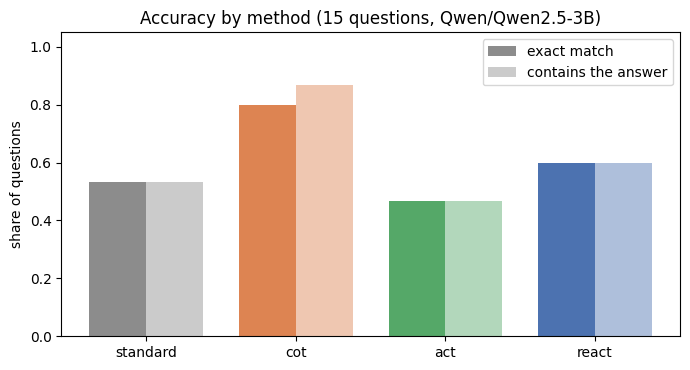

In [22]:
summary = results.groupby("method", sort=False).agg(
    exact_match=("em", "mean"), contains=("contains", "mean"),
    avg_steps=("steps", "mean"), avg_searches=("searches", "mean"), avg_prompt_tokens=("prompt_tokens", "mean")).round(3).loc[METHODS]
display(summary)

PALETTE = {"standard": "#8c8c8c", "cot": "#dd8452", "act": "#55a868", "react": "#4c72b0"}
fig, ax = plt.subplots(figsize=(7, 3.8))
x = np.arange(len(METHODS)); w = 0.38
ax.bar(x - w / 2, summary.exact_match, w, color=[PALETTE[m] for m in METHODS], label="exact match")
ax.bar(x + w / 2, summary.contains, w, color=[PALETTE[m] for m in METHODS], alpha=0.45, label="contains the answer")
ax.set_xticks(x); ax.set_xticklabels(METHODS); ax.set_ylim(0, 1.05); ax.set_ylabel("share of questions")
ax.set_title(f"Accuracy by method ({len(QUESTIONS)} questions, {MODEL_NAME if BACKEND == 'hf' else 'scripted stand-in'})")
ax.legend(); plt.tight_layout(); plt.show()

**What to look for:**
* Does **react** beat **act** (thoughts matter) and **cot/standard** (the tool matters)? The paper's pattern for a large model: ReAct beats act-only everywhere, but is close to or behind chain-of-thought on questions the model already knows.
* **avg_searches** and **avg_prompt_tokens**: the agent's accuracy costs extra model calls and a growing prompt. That is the price of grounding.
* **contains** well above **exact_match** means answers are right but verbose or oddly formatted.
* With only 15 questions, one question is 6.7 percentage points. **Small gaps are noise.**

### 📋 Report · Part 9: The scores

| method | exact match | contains | avg steps | avg searches | avg prompt tokens |
|---|---|---|---|---|---|
| standard | 0.533 (8/15) | 0.533 | 0 | 0 | 80 |
| **cot** | **0.800** (12/15) | 0.867 | 0 | 0 | 176 |
| act | 0.467 (7/15) | 0.467 | 3.93 | 3.33 | 584 |
| react | 0.600 (9/15) | 0.600 | 3.13 | 2.40 | 826 |

**Reading it**
- **Ordering: cot > react > standard > act.** Chain-of-thought, with no tool, wins.
- **react beats act by 2 questions** (0.60 vs 0.47), which is the direction the notebook expects: thoughts help the tool-user. **react is 3 questions behind cot**, which matches the notebook's "close to or behind chain-of-thought on questions the model already knows". Qwen2.5-3B clearly knows many of these facts.
- **Cost:** react uses about 10× the prompt tokens of standard and about 4.7× those of cot, and it paid that without beating cot. act makes *more* searches (3.33) than react (2.40) and more steps (3.93 vs 3.13): without thoughts it wanders. (The search counts include blocked repeats.)
- **contains vs exact match:** only cot differs (0.867 vs 0.800). One of its three misses contains the right answer in a longer form.
- **How much to trust it.** One question is 6.7 points. On the 7 questions where cot and react disagree, cot wins 5 and react wins 2, a split that a simple sign test puts at p ≈ 0.45. So the ordering of the middle three methods is not reliable; the notebook's "small gaps are noise" applies.


In [23]:
grid = results.assign(r=results.em.map({True: "yes", False: "no"})).pivot(index=["id", "kind"], columns="method", values="r")[METHODS]
display(grid)
print("Accuracy by question kind (exact match):")
display(results.groupby(["kind", "method"]).em.mean().unstack("method")[METHODS].round(2))

,method,standard,cot,act,react
id,kind,,,,
1,compare,yes,yes,yes,yes
2,compare,yes,yes,no,no
3,compare,yes,yes,no,yes
4,two_hop,no,no,no,yes
5,two_hop,no,yes,yes,yes
6,two_hop,no,yes,yes,yes
7,two_hop,no,yes,yes,yes
8,two_hop,no,yes,no,no
9,two_hop,yes,yes,yes,no


Accuracy by question kind (exact match):


method,standard,cot,act,react
kind,,,,
compare,1.00,1.00,0.50,0.50
kb_gap,1.00,0.00,0.00,0.00
one_hop,1.00,1.00,0.00,0.50
two_hop,0.12,0.75,0.62,0.75


**What to look for:** which kinds does each method fail on? A hypothesis worth testing from your own table: the tool should help most on `two_hop` and `compare`, matter little on `one_hop` facts the model may already know, and the `kb_gap` question is where tool-using agents can do *worse* than plain reasoning if they get stuck.

### 📋 Report · Part 9: Which questions worked?

| id | kind | standard | cot | act | react |
|---|---|---|---|---|---|
| 1 | compare | ✓ | ✓ | ✓ | ✓ |
| 2 | compare | ✓ | ✓ | ✗ | ✗ |
| 3 | compare | ✓ | ✓ | ✗ | ✓ |
| 15 | compare | ✓ | ✓ | ✓ | ✗ |
| 4 | two_hop | ✗ | ✗ | ✗ | **✓** |
| 5 | two_hop | ✗ | ✓ | ✓ | ✓ |
| 6 | two_hop | ✗ | ✓ | ✓ | ✓ |
| 7 | two_hop | ✗ | ✓ | ✓ | ✓ |
| 8 | two_hop | ✗ | ✓ | ✗ | ✗ |
| 9 | two_hop | ✓ | ✓ | ✓ | ✗ |
| 10 | two_hop | ✗ | ✓ | ✗ | ✓ |
| 11 | two_hop | ✗ | ✗ | ✓ | ✓ |
| 12 | one_hop | ✓ | ✓ | ✗ | ✓ |
| 13 | one_hop | ✓ | ✓ | ✗ | ✗ |
| 14 | kb_gap | ✓ | ✗ | ✗ | ✗ |

**By kind (exact match)**

| kind | standard | cot | act | react |
|---|---|---|---|---|
| compare (4) | 1.00 | 1.00 | 0.50 | 0.50 |
| two_hop (8) | **0.12** | 0.75 | 0.62 | 0.75 |
| one_hop (2) | 1.00 | 1.00 | 0.00 | 0.50 |
| kb_gap (1) | 1.00 | 0.00 | 0.00 | 0.00 |

**What it shows**
- **Two-hop questions need reasoning or a tool.** Memory with no reasoning (standard) gets 1 of 8, while cot and react each get 6 of 8, and act 5 of 8. So *some* intermediate step is the key ingredient, and cot supplies it from memory as well as the tool does.
- **react's only clear win over cot** is on question 4 and question 11 (the two two-hop questions where cot failed).
- **The notebook's hypothesis is only partly supported.** It expected the tool to help on `two_hop` (it does, versus standard, but only matches cot) and on `compare` (it does not: 0.50 against 1.00 for the memory methods). On `one_hop` the tool methods are *worse* than memory (act 0 of 2). For `kb_gap` the agents scored 0, but so did cot; only standard, which just blurted out `Isaac Newton`, got it.
- Questions 2, 8 and 13 are failed by both tool methods, and questions 9 and 15 are ones where react fails but standard, cot and act all succeed (Part 10 shows the trace for 9).


# Part 10: How did each method fail?

Right or wrong is not enough. We label every failure by its cause, following the paper's analysis of ReAct vs chain-of-thought failures.

| label | meaning |
|---|---|
| `wrong answer (no tool)` | standard or cot answered wrongly from memory |
| `loop (repeated action)` | the agent repeated a search |
| `step limit reached` | ran out of steps without `Finish` |
| `unparseable output` | no usable action |
| `answered without searching` | the agent finished with no search at all |
| `reasoning error (had the fact)` | an observation contained the gold answer but the agent answered something else |
| `search miss` | a search came back `Could not find` and the agent never recovered |
| `missing evidence` | none of the above: it finished with no relevant fact seen |

method,standard,cot,act,react
failure,,,,
correct,8,12,7,9
loop (repeated action),0,0,2,3
reasoning error (had the fact),0,0,1,1
search miss,0,0,1,1
step limit reached,0,0,4,1
wrong answer (no tool),7,3,0,0


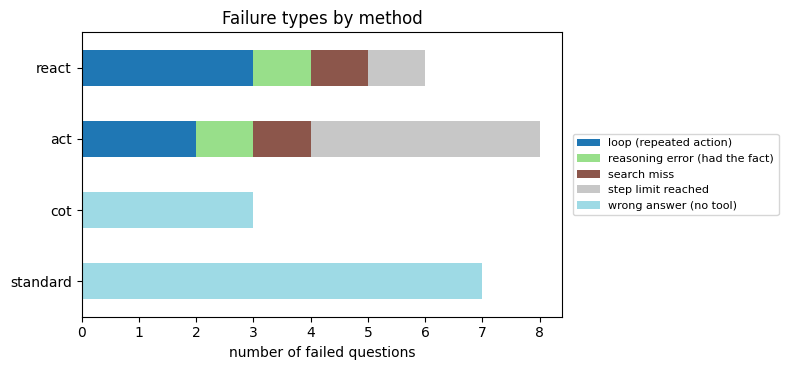

In [24]:
fails = results.assign(failure=results.failure)
tab = pd.crosstab(fails.failure, fails.method)[METHODS]
display(tab)

only_fail = tab.drop(index="correct", errors="ignore")
if only_fail.values.sum() > 0:
    ax = only_fail.T.plot.barh(stacked=True, figsize=(8, 3.8), colormap="tab20")
    ax.set_xlabel("number of failed questions"); ax.set_ylabel("")
    ax.set_title("Failure types by method")
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("No failures to plot.")

the paper found chain-of-thought failures dominated by **hallucinated facts** and ReAct failures dominated by **reasoning errors and unhelpful searches**. The table is a small-model, toy-knowledge-base version of the same question: when each method is wrong, is it because it made something up, or because it looked and still got it wrong?

### 📋 Report · Part 10: How did each method fail?

| label | standard | cot | act | react |
|---|---|---|---|---|
| correct | 8 | 12 | 7 | 9 |
| loop (repeated action) | 0 | 0 | 2 | **3** |
| reasoning error (had the fact) | 0 | 0 | 1 | 1 |
| search miss | 0 | 0 | 1 | 1 |
| step limit reached | 0 | 0 | **4** | 1 |
| wrong answer (no tool) | 7 | 3 | 0 | 0 |

**Reading it**
- **react's most common failure is a loop (3 of its 6 failures).** From the traces, the three loops are questions 2, 8 and 14. The two it does not show are questions 13 and 15; by elimination they account for the one reasoning error and the one step-limit failure.
- **act's most common failure is hitting the step limit (4 of 8).** With no thoughts, it keeps searching without deciding to finish. Thoughts helped here: react hit the limit once.
- **cot and standard fail only by "wrong answer (no tool)"** (3 and 7). That label cannot tell a hallucinated fact from a bad inference. The notebook's reference point (cot failing by hallucination, ReAct failing by reasoning errors and unhelpful searches) can only be partly tested: react's failures here are mostly loops, not reasoning errors.


In [25]:
bad = results[(results.method == "react") & (~results.em)]
print(f"{len(bad)} ReAct failures. Showing up to 3 full traces:\n")
for r_ in bad.head(3).itertuples():
    print(f"##### question {r_.id} [{r_.kind}] gold={r_.gold!r}  label: {r_.failure}")
    res = TRACES[(r_.id, "react")]
    for t in res["trace"]:
        say(f"Thought {t['step']}: {t['thought']}")
        say(f"Action {t['step']}: {t['action'] or '(no action could be parsed)'}")
        if t["observation"]:
            say(f"Observation {t['step']}: {t['observation']}")
    print(f"-> status {res['status']}, answer {res['answer']!r}\n")
if len(bad) == 0:
    print("(no failures to show)")
results.to_csv("react_results.csv", index=False)
print("saved react_results.csv")
try:
    from google.colab import files
    files.download("react_results.csv")
except Exception:
    pass

6 ReAct failures. Showing up to 3 full traces:

##### question 2 [compare] gold='Charles Babbage'  label: loop (repeated action)
Thought 1: I need to find the birth years of both Charles Babbage and Ada Lovelace.
Action 1: Search[Charles Babbage birth year]
Observation 1: Could not find [Charles Babbage birth year]. Similar: ['Charles Babbage']
Thought 2: The search did not find Charles Babbage's birth year, so I will search for his birth date.
Action 2: Search[Charles Babbage birth date]
Observation 2: Could not find [Charles Babbage birth date]. Similar: ['Charles Babbage']
Thought 3: The search did not find Charles Babbage's birth date, so I will search for his birth year.
Action 3: Search[Charles Babbage birth year]
Observation 3: (repeat: stopped)
-> status repeat, answer None

##### question 8 [two_hop] gold='2012'  label: loop (repeated action)
Thought 1: I need to find the first person to walk on the Moon and then their death year.
Action 1: Search[First person to walk on the M

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**What to look for:** open each failing trace and decide for yourself *which step went wrong*: the first thought (bad plan), a search term (wrong entity name), reading an observation (missed the fact) or the final answer (right facts, wrong conclusion). That judgement is the point of having traces.

### 📋 Report · Part 10: Three failing ReAct traces

Only the first 3 of react's 6 failures are printed (questions 2, 8 and 9).

**Question 2 (Babbage vs Lovelace), label `loop` ✗**
1. `Search[Charles Babbage birth year]` is a miss, with the suggestion `['Charles Babbage']`.
2. Thought 2 misreads the miss as "the birth year isn't there" and tries `Search[Charles Babbage birth date]`, another miss with the same suggestion.
3. Thought 3 goes back to `Search[Charles Babbage birth year]`: the **repeat** stops the run.
**Where it went wrong:** the **search term**. The model searched for a *fact* (birth year) rather than an *entity title*, and **ignored the suggestion** that was handed to it twice. Example 3 taught it to follow a suggestion, but there the suggestion differed from the query by one word.

**Question 8 (first person on the Moon), label `loop` ✗**
`Search[First person to walk on the Moon]` is a miss with **no suggestions**. Thought 2 says it will search for exactly that again, and the repeat stops the run. **Where it went wrong:** the search term again (a description, not a title like `Neil Armstrong` or `Apollo 11`), and the tool had nothing to guide it. cot answered this question correctly from memory.

**Question 9 (the Mona Lisa's museum city), label `search miss` ✗**
`Search[Museum]` misses, but the agent recovers by searching `Mona Lisa`, reads "held in the Louvre museum", and answers **`the Louvre`**. **Where it went wrong:** the final answer. It gave the result of the first hop (the museum) instead of taking the second hop to the city. The label `search miss` is misleading here: the miss was recovered, and the real failure is an answer one step short. (The label rule fires whenever an observation contains "Could not find".)


### ✍️ Draft answers to Part 11 "Write up what you found"

**1. The loop.** The five steps are: **ask** the model to continue from `Thought n:`; **cut** its output at `\nObservation`; **parse** the thought and action (forcing an action if there is none); **run** the tool (Finish ends, Search calls the knowledge base, a repeated search stops the run); **append** the Thought, Action and real Observation to the prompt. The step that would break the agent most if removed is the **cut**. In 6.2 the raw output contained a fake observation, a fake follow-up thought and an early `Finish`; without the cut the agent would have used that invention and never called the tool. With the cut, the prompt came out identical to the clean run (644 tokens).

**2. Accuracy.** Exact match: standard 0.533, cot 0.800, act 0.467, react 0.600, so cot > react > standard > act. This matches the pattern the notebook describes in one respect (react beats act, and trails cot on facts the model already knows) but not as a win for ReAct overall. The gaps are 2 questions (react over act) and 3 questions (cot over react), each larger than one question's 6.7 points. But with 15 questions this is thin: on the 7 questions where cot and react disagree, cot wins 5 to 2, which a sign test puts at p ≈ 0.45.

**3. Where the tool helped.** On `two_hop`, react got 6 of 8 and act 5 of 8, against 1 of 8 for standard, so adding any intermediate step or lookup matters. But cot also got 6 of 8, so the tool did not add anything beyond reasoning (react beat cot only on questions 4 and 11). On `compare` (0.50 vs 1.00) and `one_hop` (0.50 vs 1.00) the tool methods did worse than memory. On `kb_gap`, no agent or cot answered correctly; only standard did. So the agent did not handle it better than chain-of-thought; both failed, and react looped.

**4. Cost.** react: 2.40 searches and about 826 prompt tokens per question. act: 3.33 searches and about 584 tokens. cot: no searches and about 176 tokens. react costs about 4.7× the tokens of cot and bought 20 points *less* accuracy; against standard (about 80 tokens) it costs about 10× for about 6.7 points more. (The search counts include blocked repeats.)

**5. Failures.** react's most common failure is a loop (3 of 6); cot's failures are all "wrong answer (no tool)" (3). Taking question 2: the loop began at the **search term**. The model asked for `Charles Babbage birth year` (a fact, not a title), got a miss that suggested `Charles Babbage`, ignored the suggestion, tried `birth date`, then repeated its first query and was stopped.

**6. Compared with the paper.** Differences: a 3B model instead of 540B; a 32-article toy knowledge base instead of live Wikipedia; 3 worked examples instead of 6; 15 questions; a search that needs a near-exact title and gives spelling-based suggestions. I would expect the harness mechanics (the cut, repeat detection) and the kinds of failure it blocks to survive. I would expect the absolute scores, and the cot-versus-react ordering, to change with a bigger model or a real search tool that handles descriptions like `First person to walk on the Moon`. (That last point is my expectation, not something the notebook tests.)
